VST a nivel oracion 
1. Secuencia de frames (t,c,96,96)
2. CNN - feature extreactor - reducir dimensiones y preservar T 
3. GRU/LSTM - modelado temporal 
4. Clasificación + CTC : 71 clases de caracteres, incluido blank 

In [119]:
import json
import math
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import pyarrow

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

# Reproducibilidad
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Configuración
CLIPS_DIR = Path(r"D:\ViSpeR\clips")
METADATA_PATH = CLIPS_DIR / "metadata.json"

IMAGE_HEIGHT = 96
IMAGE_WIDTH = 96

INPUT_CHANNELS = 3  # Provisional: mas adelante enfrentamos a grayscale
VOCAB_SIZE = 71     # 70 caracteres + CTC blank

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())
print("Device:", DEVICE)
print("Metadata existe:", METADATA_PATH.exists())
print("Vocabulario:", VOCAB_SIZE)

PyTorch: 2.6.0+cu126
CUDA disponible: True
Device: cuda
Metadata existe: True
Vocabulario: 71


In [120]:
from collections import Counter
from pathlib import Path

with open(METADATA_PATH, "r", encoding="utf-8") as f:
    metadata = json.load(f)

all_text = "".join(
    info["label"] for info in metadata.values()
)

char_counts = Counter(all_text)

characters = sorted(char_counts.keys())

print(f"Cantidad de caracteres distintos: {len(characters)}")
print(f"Cantidad total con CTC blank: {len(characters) + 1}")
print("\nVocabulario:")
for i, char in enumerate(characters, start=1):
    print(f"{i:2} | {repr(char):8} | frecuencia: {char_counts[char]}")

print("\nCTC blank: 0")

Cantidad de caracteres distintos: 70
Cantidad total con CTC blank: 71

Vocabulario:
 1 | ' '      | frecuencia: 16524
 2 | '0'      | frecuencia: 57
 3 | '1'      | frecuencia: 29
 4 | '2'      | frecuencia: 29
 5 | '3'      | frecuencia: 14
 6 | '4'      | frecuencia: 11
 7 | '5'      | frecuencia: 18
 8 | '6'      | frecuencia: 3
 9 | '7'      | frecuencia: 2
10 | '8'      | frecuencia: 11
11 | '9'      | frecuencia: 8
12 | 'A'      | frecuencia: 72
13 | 'B'      | frecuencia: 25
14 | 'C'      | frecuencia: 97
15 | 'D'      | frecuencia: 29
16 | 'E'      | frecuencia: 139
17 | 'F'      | frecuencia: 12
18 | 'G'      | frecuencia: 17
19 | 'H'      | frecuencia: 26
20 | 'I'      | frecuencia: 15
21 | 'J'      | frecuencia: 6
22 | 'K'      | frecuencia: 10
23 | 'L'      | frecuencia: 56
24 | 'M'      | frecuencia: 51
25 | 'N'      | frecuencia: 47
26 | 'O'      | frecuencia: 18
27 | 'P'      | frecuencia: 86
28 | 'Q'      | frecuencia: 27
29 | 'R'      | frecuencia: 18
30 | 'S'      | f

In [121]:
IMAGE_MODE = "rgb"
INPUT_CHANNELS = 3

IMAGE_HEIGHT = 96
IMAGE_WIDTH = 96

BLANK_IDX = 0
VOCAB_SIZE = len(characters) + 1

print("Modo de imagen:", IMAGE_MODE)
print("Canales de entrada:", INPUT_CHANNELS)
print("Resolución:", IMAGE_HEIGHT, "x", IMAGE_WIDTH)
print("Tamaño del vocabulario:", VOCAB_SIZE)

Modo de imagen: rgb
Canales de entrada: 3
Resolución: 96 x 96
Tamaño del vocabulario: 71


#DATA

In [122]:
DATA_DIR = Path("data")

clips_df = pd.read_parquet(DATA_DIR / "clips_metadata.parquet")
clips_df["path"] = clips_df["path"].apply(Path)

with open(DATA_DIR / "vocabulary.json", "r", encoding="utf-8") as f:
    char_to_idx = json.load(f)

idx_to_char = {
    int(idx): char
    for char, idx in char_to_idx.items()
}

BLANK_IDX = 0
VOCAB_SIZE = len(char_to_idx) + 1

print("Clips:", len(clips_df))
print("Vocabulario:", VOCAB_SIZE)
print("Primer registro:")
display(clips_df.head(1))

Clips: 1304
Vocabulario: 71
Primer registro:


,path,label,frames,ctc_min_frames,repeated_pairs,temporal_margin,min_temporal_ratio,duration_seconds,words_per_second,video_id,is_ctc_problematic,frames_after_x1,margin_after_x1,frames_after_x2,margin_after_x2,frames_after_x3,margin_after_x3,frames_after_x4,margin_after_x4
0,D:\ViSpeR\clips\videos\0YEeb-WLF2w\00000.mp4,La ficción es una herramienta poderosa,108,41,2,67,0.37963,4.32,1.388889,0YEeb-WLF2w,False,108,67,54,13,36,-5,27,-14


In [123]:
class ViSpeRDataset(Dataset):
    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        cap = cv2.VideoCapture(str(row["path"]))

        if not cap.isOpened():
            raise RuntimeError(f"No se pudo abrir: {row['path']}")

        frames = []

        while True:
            ret, frame = cap.read()

            if not ret:
                break

            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frames.append(frame)

        cap.release()

        if not frames:
            raise RuntimeError(f"El clip no contiene frames: {row['path']}")

        video = np.stack(frames).astype(np.float32) / 255.0
        video = torch.from_numpy(video).permute(0, 3, 1, 2)

        target = torch.tensor(
            [char_to_idx[char] for char in str(row["label"])],
            dtype=torch.long
        )

        return {
            "video": video,
            "target": target,
            "input_length": video.shape[0],
            "target_length": target.numel(),
            "text": str(row["label"]),
            "path": str(row["path"])
        }

la STCNN va a procesar grupos de frames simultaneamente (menos mal)
Los videos tienen 3 dim relevantes_> h,w,t
conv3d , cada frame va a observar una secuencia, y va a extraer caract de eso
approx 1 +3(3-1) /(25fps) = 0.28s de contexto local 

In [124]:

class STCNN(nn.Module):
    def __init__(self, in_channels=3):
        super().__init__()

        self.block1 = nn.Sequential(
            nn.Conv3d(
                in_channels, 32,
                kernel_size=(3, 5, 5),
                stride=(1, 2, 2),
                padding=(1, 2, 2)
            ),
            nn.ReLU(),
            nn.MaxPool3d(
                kernel_size=(1, 2, 2),
                stride=(1, 2, 2)
            ),
            nn.Dropout3d(p=0.5)
        )

        self.block2 = nn.Sequential(
            nn.Conv3d(
                32, 64,
                kernel_size=(3, 5, 5),
                stride=(1, 1, 1),
                padding=(1, 2, 2)
            ),
            nn.ReLU(),
            nn.MaxPool3d(
                kernel_size=(1, 2, 2),
                stride=(1, 2, 2)
            ),
            nn.Dropout3d(p=0.5)
        )

        self.block3 = nn.Sequential(
            nn.Conv3d(
                64, 96,
                kernel_size=(3, 3, 3),
                stride=(1, 1, 1),
                padding=(1, 1, 1)
            ),
            nn.ReLU(),
            nn.MaxPool3d(
                kernel_size=(1, 2, 2),
                stride=(1, 2, 2)
            ),
            nn.Dropout3d(p=0.5)
        )

    def apply_temporal_mask(self, x, lengths):
        # x: (B, C, T, H, W)
        temporal_size = x.size(2)

        valid_positions = (
            torch.arange(temporal_size, device=x.device)[None, :]
            < lengths.to(x.device)[:, None]
        )

        # (B, 1, T, 1, 1)
        mask = valid_positions[:, None, :, None, None]

        return x * mask

    def forward(self, x, lengths):
        x = self.block1(x)
        x = self.apply_temporal_mask(x, lengths)

        x = self.block2(x)
        x = self.apply_temporal_mask(x, lengths)

        x = self.block3(x)
        x = self.apply_temporal_mask(x, lengths)

        return x


In [125]:
# test ficticio 
model_cnn = STCNN(in_channels=INPUT_CHANNELS)
lengths = torch.tensor([75, 75])

x = torch.randn(2, 3, 75, 96, 96)

with torch.no_grad():
    features = model_cnn(x,lengths)

print("Input:", x.shape)
print("Output:", features.shape)

assert features.shape == (2, 96, 75, 6, 6)

print("Dimensiones verificadas correctamente.")

Input: torch.Size([2, 3, 75, 96, 96])
Output: torch.Size([2, 96, 75, 6, 6])
Dimensiones verificadas correctamente.


### preparar la salida a la recurrente 
$ F = 96 \times 6 \times 6 = 3456 $  

cada frame va a quedar representado por un vector de 3456 características. nothermione,notme,you

In [126]:
# (B, C, T, H, W) -> (T, B, C, H, W)
features = features.permute(2, 0, 1, 3, 4)

# (T, B, C, H, W) -> (T, B, F)
features = features.reshape(
    features.shape[0],
    features.shape[1],
    -1
)

print("Features para la RNN:", features.shape)

assert features.shape == (75, 2, 3456)

Features para la RNN: torch.Size([75, 2, 3456])


In [127]:
class TemporalEncoder(nn.Module):
    def __init__(
        self,
        input_size=3456,
        hidden_size=256,
        num_layers=2,
        rnn_type="gru"
    ):
        super().__init__()

        if rnn_type.lower() == "gru":
            rnn_class = nn.GRU
        elif rnn_type.lower() == "lstm":
            rnn_class = nn.LSTM
        else:
            raise ValueError("rnn_type debe ser 'gru' o 'lstm'")

        self.rnn = rnn_class(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            bidirectional=True,
            batch_first=False
        )

    def forward(self, x, lengths):
        packed = pack_padded_sequence(
            x,
            lengths.cpu(),
            batch_first=False,
            enforce_sorted=False
        )

        packed_output, _ = self.rnn(packed)

        output, _ = pad_packed_sequence(
            packed_output,
            batch_first=False,
            total_length=x.size(0)
        )

        return output

In [128]:
class CharacterClassifier(nn.Module):
    def __init__(self, input_size=512, vocab_size=VOCAB_SIZE):
        super().__init__()
        self.linear = nn.Linear(input_size, vocab_size)

    def forward(self, x):
        return self.linear(x)

#cosillas:
la entrada es lo que devuelve el dataLoader -> $(B,T,C,H,W)$
La salida queda en (T,B,V), que es el formato que quiere CTCLoss

In [129]:
class LipReadingModel(nn.Module):
    def __init__(
        self,
        in_channels=3,
        vocab_size=VOCAB_SIZE,
        hidden_size=256,
        rnn_type="gru"
    ):
        super().__init__()

        self.visual_encoder = STCNN(in_channels=in_channels)

        self.temporal_encoder = TemporalEncoder(
            input_size=96 * 6 * 6,
            hidden_size=hidden_size,
            num_layers=2,
            rnn_type=rnn_type
        )

        self.classifier = CharacterClassifier(
            input_size=hidden_size * 2,
            vocab_size=vocab_size
        )

    def forward(self, x, input_lengths):
        # B,T,C,H,W -> B,C,T,H,W
        x = x.permute(0, 2, 1, 3, 4)

        # Extracción de características espacio-temporales
        x = self.visual_encoder(x, input_lengths)

        # B,C,T,H,W -> T,B,C*H*W
        x = x.permute(2, 0, 1, 3, 4)
        x = x.reshape(x.shape[0], x.shape[1], -1)

        # Modelado temporal respetando las longitudes reales
        x = self.temporal_encoder(x, input_lengths)

        # Clasificación por timestep
        x = self.classifier(x)

        return torch.log_softmax(x, dim=-1)

In [130]:
train_dataset = ViSpeRDataset(clips_df) 

sample = train_dataset[0]

print("Video:", sample["video"].shape)
print("Tipo:", sample["video"].dtype)
print("Rango:", sample["video"].min().item(), sample["video"].max().item())
print("Target:", sample["target"].shape)
print("Texto:", sample["text"])

assert sample["video"].ndim == 4
assert sample["video"].shape[1:] == (3, 96, 96)
assert sample["video"].dtype == torch.float32
assert sample["target"].numel() == len(sample["text"])

print("\nValidación correcta.")

Video: torch.Size([108, 3, 96, 96])
Tipo: torch.float32
Rango: 0.0 1.0
Target: torch.Size([39])
Texto:  La ficción es una herramienta poderosa

Validación correcta.


In [131]:
def collate_fn(batch):
    videos = [item["video"] for item in batch]
    targets = [item["target"] for item in batch]

    input_lengths = torch.tensor(
        [video.shape[0] for video in videos],
        dtype=torch.long
    )

    target_lengths = torch.tensor(
        [target.numel() for target in targets],
        dtype=torch.long
    )

    max_frames = input_lengths.max().item()

    padded_videos = torch.zeros(
        len(batch),
        max_frames,
        *videos[0].shape[1:],
        dtype=torch.float32
    )

    for i, video in enumerate(videos):
        padded_videos[i, :video.shape[0]] = video

    concatenated_targets = torch.cat(targets)

    return {
        "videos": padded_videos,
        "targets": concatenated_targets,
        "input_lengths": input_lengths,
        "target_lengths": target_lengths,
        "texts": [item["text"] for item in batch],
        "paths": [item["path"] for item in batch]
    }

In [132]:
BATCH_SIZE = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0
)

batch = next(iter(train_loader))

print("Videos:", batch["videos"].shape)
print("Targets:", batch["targets"].shape)
print("Input lengths:", batch["input_lengths"])
print("Target lengths:", batch["target_lengths"])
print("Transcripciones:")

for text in batch["texts"]:
    print(repr(text))

Videos: torch.Size([2, 108, 3, 96, 96])
Targets: torch.Size([61])
Input lengths: tensor([108,  82])
Target lengths: tensor([39, 22])
Transcripciones:
' La ficción es una herramienta poderosa'
' Una tecnología blanda'


In [133]:
from torch.nn.utils.rnn import (
    pack_padded_sequence,
    pad_packed_sequence
)

blank=0: indice blank  
reduction="mean": promedia la pérdida del batch.  
zero_infinity=True: evita que pérdidas infinitas por alineaciones imposibles contaminen el entrenamiento.  

In [134]:
# la funcion de perdida 
ctc_loss = nn.CTCLoss(
    blank=BLANK_IDX,
    reduction="mean",
    zero_infinity=True
)

## TRAIN

In [135]:
print("Columnas:", clips_df.columns.tolist())

display(clips_df[["path", "label", "frames"]].head())

print("\nCantidad de clips:", len(clips_df))

Columnas: ['path', 'label', 'frames', 'ctc_min_frames', 'repeated_pairs', 'temporal_margin', 'min_temporal_ratio', 'duration_seconds', 'words_per_second', 'video_id', 'is_ctc_problematic', 'frames_after_x1', 'margin_after_x1', 'frames_after_x2', 'margin_after_x2', 'frames_after_x3', 'margin_after_x3', 'frames_after_x4', 'margin_after_x4']


,path,label,frames
0,D:\ViSpeR\clips\videos\0YEeb-WLF2w\00000.mp4,La ficción es una herramienta poderosa,108
1,D:\ViSpeR\clips\videos\0YEeb-WLF2w\00001.mp4,Una tecnología blanda,82
2,D:\ViSpeR\clips\videos\0YEeb-WLF2w\00002.mp4,Las tecnologías blandas funcionan de la misma...,79
3,D:\ViSpeR\clips\videos\0YEeb-WLF2w\00003.mp4,Cuando en las historias de la Biblia se nos c...,178
4,D:\ViSpeR\clips\videos\0YEeb-WLF2w\00004.mp4,que las cosas buenas son recompensadas y las ...,110



Cantidad de clips: 1304


In [136]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=18
)

train_idx, test_idx = next(
    splitter.split(
        clips_df,
        groups=clips_df["video_id"]
    )
)

train_df = clips_df.iloc[train_idx].reset_index(drop=True)
test_df = clips_df.iloc[test_idx].reset_index(drop=True)

print("TRAIN")
print("Videos:", train_df["video_id"].nunique())
print("Clips:", len(train_df))

print("\nTEST")
print("Videos:", test_df["video_id"].nunique())
print("Clips:", len(test_df))

print(
    "\n¿Hay videos compartidos?",
    bool(
        set(train_df["video_id"])
        & set(test_df["video_id"])
    )
)

TRAIN
Videos: 18
Clips: 947

TEST
Videos: 5
Clips: 357

¿Hay videos compartidos? False


In [137]:
from torch.utils.data import DataLoader

train_dataset = ViSpeRDataset(train_df)
test_dataset = ViSpeRDataset(test_df)

train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=2,
    shuffle=False,
    collate_fn=collate_fn
)

print("Train:", len(train_dataset), "clips |", len(train_loader), "batches")
print("Test:", len(test_dataset), "clips |", len(test_loader), "batches")

Train: 947 clips | 474 batches
Test: 357 clips | 179 batches


In [138]:
model = LipReadingModel(
    in_channels=INPUT_CHANNELS,
    vocab_size=VOCAB_SIZE,
    hidden_size=256,
    rnn_type="gru"
).to(DEVICE)

print("Modelo reinicializado")
print("Dispositivo:", next(model.parameters()).device)

Modelo reinicializado
Dispositivo: cuda:0


# train posta

Época 1/5 | Loss: 3.1216 | Batches: 474/474
Época 2/5 | Loss: 3.0002 | Batches: 474/474
Época 3/5 | Loss: 2.9919 | Batches: 474/474
Época 4/5 | Loss: 2.9846 | Batches: 474/474
Época 5/5 | Loss: 2.9777 | Batches: 474/474


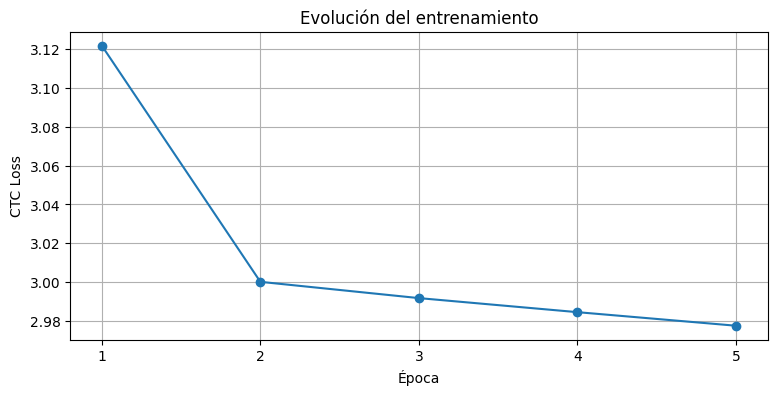

In [139]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

EPOCHS = 5

ctc_loss = nn.CTCLoss(
    blank=BLANK_IDX,
    reduction="mean",
    zero_infinity=True
)

optimizer = optim.Adam(
    model.parameters(),
    lr=1e-4
)

history = []

for epoch in range(EPOCHS):

    model.train()
    total_loss = 0.0
    valid_batches = 0

    for batch_idx, batch in enumerate(train_loader):

        videos = batch["videos"].to(DEVICE)
        targets = batch["targets"].to(DEVICE)

        input_lengths = batch["input_lengths"]
        target_lengths = batch["target_lengths"]

        optimizer.zero_grad()

        log_probs = model(videos, input_lengths)

        loss = ctc_loss(
            log_probs,
            targets,
            input_lengths,
            target_lengths
        )

        if not torch.isfinite(loss):
            continue

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0
        )

        optimizer.step()

        total_loss += loss.item()
        valid_batches += 1

    epoch_loss = total_loss / valid_batches
    history.append(epoch_loss)

    print(
        f"Época {epoch + 1}/{EPOCHS} | "
        f"Loss: {epoch_loss:.4f} | "
        f"Batches: {valid_batches}/{len(train_loader)}"
    )

plt.figure(figsize=(9, 4))
plt.plot(range(1, EPOCHS + 1), history, marker="o")
plt.xlabel("Época")
plt.ylabel("CTC Loss")
plt.title("Evolución del entrenamiento")
plt.xticks(range(1, EPOCHS + 1))
plt.grid(True)
plt.show()

## eval

In [140]:
def greedy_decode(log_probs, input_length):
    """
    Convierte las predicciones por timestep en una secuencia
    de caracteres usando greedy decoding + CTC collapse.
    """

    predictions = log_probs[:input_length].argmax(dim=-1).tolist()

    decoded = []
    previous = None

    for token in predictions:

        if token != previous and token != BLANK_IDX:
            decoded.append(idx_to_char[token])

        previous = token

    return "".join(decoded)


def edit_distance(reference, hypothesis):
    """
    Distancia de Levenshtein:
    sustituciones + inserciones + eliminaciones.
    """

    rows = len(reference) + 1
    cols = len(hypothesis) + 1

    dp = [[0] * cols for _ in range(rows)]

    for i in range(rows):
        dp[i][0] = i

    for j in range(cols):
        dp[0][j] = j

    for i in range(1, rows):
        for j in range(1, cols):

            if reference[i - 1] == hypothesis[j - 1]:
                cost = 0
            else:
                cost = 1

            dp[i][j] = min(
                dp[i - 1][j] + 1,       # Eliminación
                dp[i][j - 1] + 1,       # Inserción
                dp[i - 1][j - 1] + cost  # Sustitución
            )

    return dp[-1][-1]


def normalize_text(text):
    """
    Normalización mínima para comparar transcripciones.
    """

    return " ".join(text.lower().split())


In [141]:
ctc_loss = nn.CTCLoss(
    blank=BLANK_IDX,
    reduction="mean",
    zero_infinity=True
)

model.eval()

total_loss = 0.0
valid_batches = 0

total_char_errors = 0
total_chars = 0

total_word_errors = 0
total_words = 0

results = []


In [142]:

with torch.no_grad():

    for batch in test_loader:

        videos = batch["videos"].to(DEVICE)
        targets = batch["targets"].to(DEVICE)

        input_lengths = batch["input_lengths"]
        target_lengths = batch["target_lengths"]

        # Forward
        log_probs = model(videos, input_lengths)

        # CTC Loss
        loss = ctc_loss(
            log_probs,
            targets,
            input_lengths,
            target_lengths
        )

        if torch.isfinite(loss):
            total_loss += loss.item()
            valid_batches += 1

        # Decodificar cada video del batch
        target_offset = 0

        for i in range(len(input_lengths)):

            # Predicción
            prediction = greedy_decode(
                log_probs[:, i, :],
                input_lengths[i].item()
            )

            # Target correspondiente al video
            target_length = target_lengths[i].item()

            target = targets[
                target_offset:target_offset + target_length
            ].tolist()

            reference = "".join(
                idx_to_char[token]
                for token in target
            )

            target_offset += target_length

            # Normalización
            reference_norm = normalize_text(reference)
            prediction_norm = normalize_text(prediction)

            # CER
            char_errors = edit_distance(
                reference_norm,
                prediction_norm
            )

            total_char_errors += char_errors
            total_chars += len(reference_norm)

            # WER
            reference_words = reference_norm.split()
            prediction_words = prediction_norm.split()

            word_errors = edit_distance(
                reference_words,
                prediction_words
            )

            total_word_errors += word_errors
            total_words += len(reference_words)

            results.append({
                "reference": reference,
                "prediction": prediction,
                "char_errors": char_errors,
                "word_errors": word_errors
            })

In [143]:
test_loss = (
    total_loss / valid_batches
    if valid_batches > 0 else float("nan")
)

CER = (
    total_char_errors / total_chars
    if total_chars > 0 else float("nan")
)

WER = (
    total_word_errors / total_words
    if total_words > 0 else float("nan")
)

In [144]:
print("=" * 50)
print("RESULTADOS DE EVALUACIÓN")
print("=" * 50)

print(f"Clips evaluados: {len(results)}")
print(f"Test Loss:       {test_loss:.4f}")
print(f"CER:             {CER:.4f} ({CER * 100:.2f}%)")
print(f"WER:             {WER:.4f} ({WER * 100:.2f}%)")

print("\n" + "=" * 50)
print("EJEMPLOS DE PREDICCIONES")
print("=" * 50)

for i, result in enumerate(results[:10]):

    print(f"\nEjemplo {i + 1}")
    print("Real:      ", repr(result["reference"]))
    print("Predicción:", repr(result["prediction"]))
    print("Errores de caracteres:", result["char_errors"])
    print("Errores de palabras:  ", result["word_errors"])


print("\n" + "=" * 50)
print("DISTRIBUCIÓN DE PREDICCIONES")
print("=" * 50)

from collections import Counter

prediction_counts = Counter(
    result["prediction"] for result in results
)

for prediction, count in prediction_counts.most_common(15):
    print(f"{repr(prediction):30s} {count}")

RESULTADOS DE EVALUACIÓN
Clips evaluados: 357
Test Loss:       2.9117
CER:             0.9997 (99.97%)
WER:             1.0000 (100.00%)

EJEMPLOS DE PREDICCIONES

Ejemplo 1
Real:       ' La ficción es una herramienta poderosa'
Predicción: ' '
Errores de caracteres: 38
Errores de palabras:   6

Ejemplo 2
Real:       ' Una tecnología blanda'
Predicción: ' '
Errores de caracteres: 21
Errores de palabras:   3

Ejemplo 3
Real:       ' Las tecnologías blandas funcionan de la misma manera'
Predicción: ' '
Errores de caracteres: 52
Errores de palabras:   8

Ejemplo 4
Real:       ' Cuando en las historias de la Biblia se nos cuenta que hay cosas que son correctas y hay cosas que son incorrectas'
Predicción: ' '
Errores de caracteres: 114
Errores de palabras:   22

Ejemplo 5
Real:       ' que las cosas buenas son recompensadas y las cosas malas son castigadas'
Predicción: ' '
Errores de caracteres: 71
Errores de palabras:   12

Ejemplo 6
Real:       ' la ficción lo que está haciendo es darnos u